# Projekt 2 - Low light image enhancement: baseline, trening, ewaluacja

Ten notebook działa **w Colabie i lokalnie** (na komputerze z GPU). Przygotowanie danych jest w `00_data_preparation.ipynb`.

Plik zawiera części takie jak:
1. **baseline:** wyrównanie histogramu na zbiorze testowym (20 ostatnich obrazów),
2. **trening** sieci U-Net (jeśli model już istnieje w folderze `runs`, trening jest pomijany),
3. **ewaluacja** na zbiorze testowym: tabela `baseline` / `network`, wizualizacje, analiza przepaleń.

**Uruchomienie Lokalne:** umieść ten notebook w folderze z plikami `.py` i `RAISE_258.csv`, a obrazy (foldery `gt` i `dark`) w folderze `lowlight_data`.
Potrzebny jest PyTorch z obsługą karty (instalacja ze strony pytorch.org); resztę bibliotek notebook doinstaluje sam.

## 1. Ustawienia środowiska wykonawczego

In [1]:
import os, sys

IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    CODE_DIR = '/content/drive/MyDrive/sigk_lowlight'     # .py files, the csv, models and results (on Drive)
    DATA_DIR = '/content/lowlight_data'                    # local copy of the images (faster than Drive)
else:
    CODE_DIR = '.'                                         # folder with the .py files and the csv
    DATA_DIR = 'lowlight_data'                             # folder with the subfolders gt/ and dark/

CSV_PATH = os.path.join(CODE_DIR, 'RAISE_258.csv')
RUNS_DIR = os.path.join(CODE_DIR, 'runs')                  # trained models and training history
RESULTS_DIR = os.path.join(CODE_DIR, 'results')            # tables and figures
os.makedirs(RESULTS_DIR, exist_ok=True)
sys.path.append(CODE_DIR)

print('Colab:', IN_COLAB, '| csv exists:', os.path.exists(CSV_PATH))

Mounted at /content/drive
Colab: True | csv exists: True


In [2]:
# install missing libraries (PyTorch itself has to be installed by hand locally)
import subprocess

def ensure(package, module):
    try:
        __import__(module)
    except ImportError:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', package])

for package, module in [('lpips', 'lpips'), ('torchmetrics', 'torchmetrics'), ('pandas', 'pandas'),
                        ('opencv-python', 'cv2'), ('matplotlib', 'matplotlib')]:
    ensure(package, module)

In [3]:
import json
import shutil

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import lpips
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader

from dataset import LowLightDataset, read_names, split_names
from baselines import histogram_equalization
from metrics import all_metrics
from models import UNet
from train import train

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device, '|', torch.cuda.get_device_name(0) if device == 'cuda' else 'NO GPU - training will be very slow')

device: cuda | Tesla T4


### Dane
W Colabie kopiujemy obrazy z Dysku na lokalny dysk (czytanie z Dysku w każdej epoce jest bardzo wolne). Lokalnie obrazy muszą być w `DATA_DIR`.

In [4]:
if IN_COLAB and not os.path.exists(DATA_DIR):
    for name in ('lowlight_data', 'data'):                 # the two names of the backup folder we used
        source = os.path.join(CODE_DIR, name)
        if os.path.exists(os.path.join(source, 'gt')):
            shutil.copytree(source, DATA_DIR)
            break

assert os.path.exists(os.path.join(DATA_DIR, 'gt')), f'No images in {DATA_DIR} (folders gt/ and dark/ are needed)'
print('gt:', len(os.listdir(os.path.join(DATA_DIR, 'gt'))), '| dark:', len(os.listdir(os.path.join(DATA_DIR, 'dark'))))

train_names, val_names, test_names = split_names(read_names(CSV_PATH))
print('train:', len(train_names), '| val:', len(val_names), '| test:', len(test_names))

gt: 100 | dark: 100
train: 72 | val: 8 | test: 20


## 2. Funkcje do ewaluacji
* `predict_padded`: U-Net trzy razy zmniejsza obraz o połowę, więc wysokość i szerokość muszą dzielić się przez 8. Zdjęcia testowe (np. 1640 x 2474) tego nie spełniają, więc dodajemy brzeg (odbicie lustrzane), uruchamiamy sieć i przycinamy wynik.
* `run_test`: dla każdego obrazu testowego liczy PSNR, SSIM i LPIPS dla: ciemnego wejścia, baseline'u i sieci (całe obrazy, nie wycinki).

In [5]:
lpips_model = lpips.LPIPS(net='alex').to(device)
test_ds = LowLightDataset(DATA_DIR, test_names, mode='test')
test_dl = DataLoader(test_ds, batch_size=1, shuffle=False)


def predict_padded(model, x, multiple=8):
    _, _, h, w = x.shape
    pad_h = (-h) % multiple
    pad_w = (-w) % multiple
    x_pad = F.pad(x, (0, pad_w, 0, pad_h), mode='reflect')      # (left, right, top, bottom)
    return model(x_pad)[:, :, :h, :w]


def load_unet(name):
    model = UNet().to(device)
    model.load_state_dict(torch.load(os.path.join(RUNS_DIR, name, 'best.pt'), map_location=device, weights_only=True))
    model.eval()
    return model


def run_test(models):
    # models: dictionary {name: trained model}; returns metrics of every test image and every method
    rows = []
    with torch.no_grad():
        for image_name, (dark, gt) in zip(test_names, test_dl):
            outputs = {'dark input': dark, 'baseline': histogram_equalization(dark)}
            for model_name, model in models.items():
                outputs[f'network ({model_name})'] = predict_padded(model, dark.to(device)).cpu()
            for method, pred in outputs.items():
                m = all_metrics(pred.clamp(0, 1).to(device), gt.to(device), lpips_model)
                rows.append({'image': image_name, 'method': method, 'PSNR': m['PSNR'].item(),
                             'SSIM': m['SSIM'].item(), 'LPIPS': m['LPIPS'].item()})
    return pd.DataFrame(rows)

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 124MB/s]


Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/alex.pth


## 3. Baseline (przed treningiem)
Wyrównanie histogramu na kanale jasności, liczone na 20 obrazach testowych.

In [6]:
per_image = run_test({})
table = per_image.groupby('method', sort=False)[['PSNR', 'SSIM', 'LPIPS']].mean()
table.round(4)

/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:70: FutureWarning: Importing `spectral_angle_mapper` from `torchmetrics.functional` was deprecated and will be removed in 2.0. Import `spectral_angle_mapper` from `torchmetrics.image` instead.
  _future_warning(


,PSNR,SSIM,LPIPS
method,,,
dark input,11.7857,0.2600,0.7397
baseline,11.3147,0.1455,1.0770


## 4. Trening
Osobny model dla każdej wartości wagi LPIPS w funkcji straty (`0.0` = tylko L1). Wynik każdego treningu trafia do `runs/<nazwa>/` (`best.pt`, `history.json`).
**Jeśli model o danej nazwie już istnieje, trening jest pomijany**.
Aby wytrenować od nowa, usuń folder modelu albo ustaw `RETRAIN = True`.

In [7]:
EPOCHS = 50
RETRAIN = False
experiments = {'unet_l1': 0.0, 'unet_lpips': 0.05}      # name -> weight of the LPIPS part of the loss

for name, lpips_weight in experiments.items():
    out_dir = os.path.join(RUNS_DIR, name)
    if os.path.exists(os.path.join(out_dir, 'best.pt')) and not RETRAIN:
        print(f'{name}: model already exists, training skipped')
        continue
    print(f'=== training {name} ===')
    train(DATA_DIR, CSV_PATH, out_dir, epochs=EPOCHS, lpips_weight=lpips_weight)

unet_l1: model already exists, training skipped
=== training unet_lpips ===
Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/alex.pth
device: cuda
train crops per epoch: 1440
val crops: 32
seed: 0
epoch 1: loss 0.1821 | val PSNR 14.98 | lr 0.000200 | 54s
  -> saved best model (PSNR: 14.98)
epoch 2: loss 0.1161 | val PSNR 16.28 | lr 0.000199 | 55s
  -> saved best model (PSNR: 16.28)
epoch 3: loss 0.1060 | val PSNR 16.59 | lr 0.000198 | 55s
  -> saved best model (PSNR: 16.59)
epoch 4: loss 0.1015 | val PSNR 17.30 | lr 0.000197 | 54s
  -> saved best model (PSNR: 17.30)
epoch 5: loss 0.1007 | val PSNR 17.26 | lr 0.000195 | 55s
epoch 6: loss 0.0993 | val PSNR 17.00 | lr 0.000193 | 54s
epoch 7: loss 0.0956 | val PSNR 17.25 | lr 0.000190 | 55s
epoch 8: loss 0.0957 | val PSNR 17.18 | lr 0.000188 | 55s
epoch 9: loss 0.0949 | val PSNR 17.59 | lr 0.000184 | 54s
  -> saved best model (PSNR: 17.59)
epoch 10: loss 0.0927 | val PSNR 17.71 | lr 0.000181 | 54s
  -> saved best model (PSNR: 17.71)
epoch 11: loss 0.0911 | val PSNR 17.76 | lr 0.000177

### Krzywe uczenia

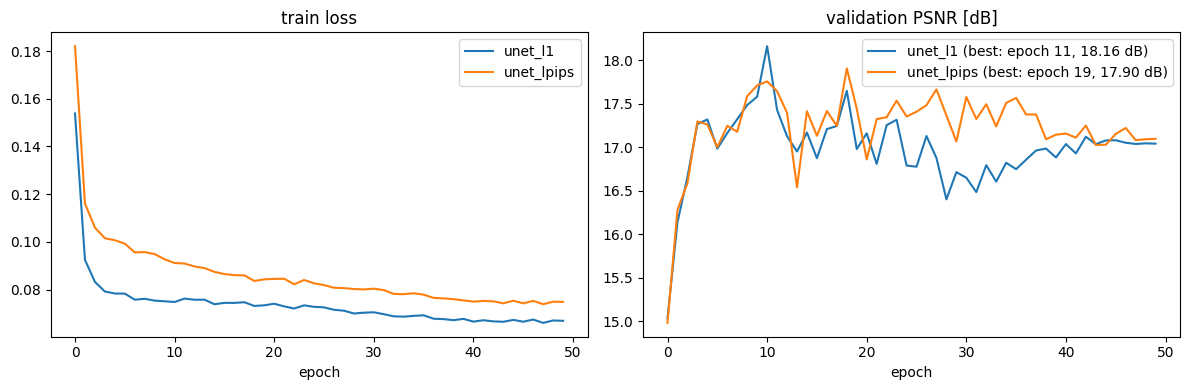

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name in experiments:
    path = os.path.join(RUNS_DIR, name, 'history.json')
    if not os.path.exists(path):
        continue
    h = json.load(open(path, encoding='utf-8'))
    val = [e['val_psnr'] for e in h]
    best = int(np.argmax(val))
    axes[0].plot([e['loss'] for e in h], label=name)
    axes[1].plot(val, label=f'{name} (best: epoch {best + 1}, {val[best]:.2f} dB)')
axes[0].set_title('train loss')
axes[1].set_title('validation PSNR [dB]')
for ax in axes:
    ax.set_xlabel('epoch')
    ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'training_curves.png'), dpi=150)
plt.show()

## 5. Wyniki na zbiorze testowym
Tabela dla 20 ostatnich obrazów (całe obrazy). PSNR i SSIM: wyżej = lepiej, LPIPS: niżej = lepiej.

In [9]:
models = {name: load_unet(name) for name in experiments if os.path.exists(os.path.join(RUNS_DIR, name, 'best.pt'))}
per_image = run_test(models)
per_image.to_csv(os.path.join(RESULTS_DIR, 'per_image.csv'), index=False)

table = per_image.groupby('method', sort=False)[['PSNR', 'SSIM', 'LPIPS']].mean()
table.to_csv(os.path.join(RESULTS_DIR, 'results.csv'))
table.round(4)

/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:70: FutureWarning: Importing `spectral_angle_mapper` from `torchmetrics.functional` was deprecated and will be removed in 2.0. Import `spectral_angle_mapper` from `torchmetrics.image` instead.
  _future_warning(


,PSNR,SSIM,LPIPS
method,,,
dark input,11.7857,0.2600,0.7397
baseline,11.3147,0.1455,1.0770
network (unet_l1),20.2358,0.3992,0.5286
network (unet_lpips),20.5085,0.4258,0.3902


## 6. Wizualizacje
Ciemny obraz na wejściu, baseline, sieć i obraz wzorcowy dla najlepszego i najgorszego obrazu testowego oraz dla pierwszego obrazu.

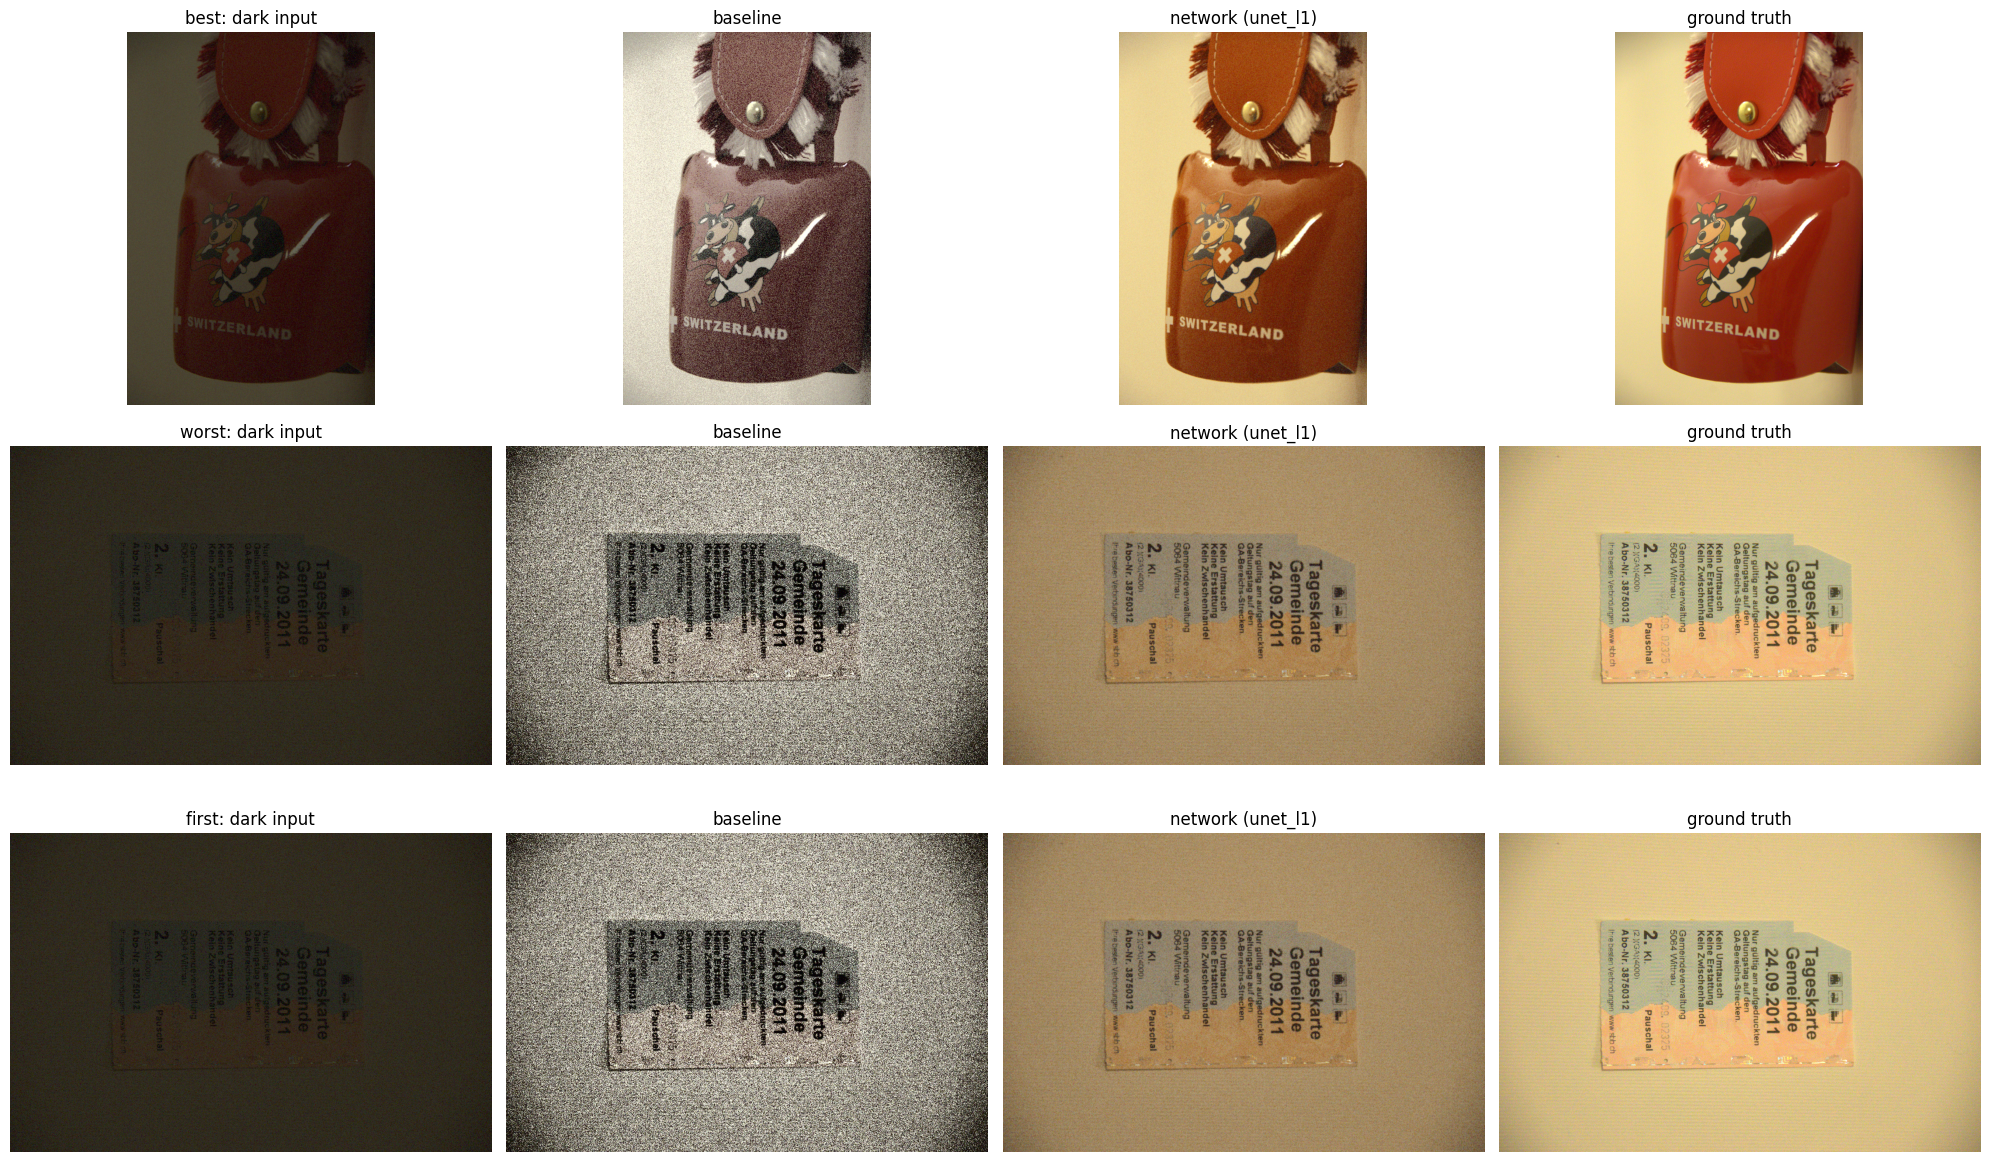

In [10]:
main_name = list(models)[0]                                     # which network to show (change if needed)
model = models[main_name]
net = per_image[per_image.method == f'network ({main_name})'].reset_index(drop=True)
picked = [int(net['PSNR'].idxmax()), int(net['PSNR'].idxmin()), 0]
titles = ['best', 'worst', 'first']


def small(t):
    return t[0].clamp(0, 1).permute(1, 2, 0).cpu().numpy()[::3, ::3]      # every 3rd pixel, the figure stays small


fig, axes = plt.subplots(len(picked), 4, figsize=(20, 4 * len(picked)))
for r, i in enumerate(picked):
    dark, gt = test_ds[i]
    dark, gt = dark.unsqueeze(0), gt.unsqueeze(0)
    with torch.no_grad():
        out = predict_padded(model, dark.to(device)).cpu()
    panels = [('dark input', dark), ('baseline', histogram_equalization(dark)),
              (f'network ({main_name})', out), ('ground truth', gt)]
    for col, (title, img) in enumerate(panels):
        axes[r, col].imshow(small(img))
        axes[r, col].set_title(f'{titles[r]}: {title}' if col == 0 else title)
        axes[r, col].axis('off')
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'examples.png'), dpi=100)
plt.show()

## 7. Przypadki specjalne - przepalenia
Dla każdego obrazu testowego liczymy, jaki odsetek pikseli obrazu wzorcowego jest przepalony (którykolwiek kanał >= 250), i zestawiamy to z PSNR.

In [11]:
saturated = [float((test_ds.gt[i].max(axis=2) >= 250).mean()) * 100 for i in range(len(test_ds))]

summary = pd.DataFrame({'image': test_names, 'saturated [%]': saturated})
for method in per_image.method.unique():
    values = per_image[per_image.method == method].reset_index(drop=True)['PSNR']
    summary[f'PSNR {method}'] = values
summary.sort_values('saturated [%]', ascending=False).round(2)

,image,saturated [%],PSNR dark input,PSNR baseline,PSNR network (unet_l1),PSNR network (unet_lpips)
18,redaf7d93t,12.40,10.82,15.38,16.28,17.39
13,r7964e5f8t,5.84,15.42,7.43,19.65,20.21
14,r35f565f8t,5.29,14.52,8.24,17.80,18.15
6,r754ef33et,5.14,13.57,10.77,19.69,21.42
2,r19d72b0ct,3.65,8.57,15.39,24.34,23.71
3,r5211d294t,3.14,6.77,14.56,19.65,18.04
11,r43b830fet,3.00,16.65,7.00,19.61,20.14
1,r8e60f7d2t,2.62,6.05,12.42,17.76,16.32
0,rc589a8d6t,2.44,5.09,9.49,14.00,12.99
15,r2f910937t,2.01,19.16,5.92,21.47,23.18
